# Docstrings & Structured Output

Docstrings do two different jobs in an agent:

| Where | What the docstring controls |
|---|---|
| **Tool** function (`@tool`) | *When* and *how* the model calls the tool (the **input**) |
| **Pydantic** class (`BaseModel`) | The **shape of the model's answer** (the **output**) |

**Plan:**
1. Setup
2. Tool docstrings: what the model actually sees
3. `parse_docstring=True`: describe each argument
4. Formatting what a tool *returns* (what the model reads)
5. Structured output with a Pydantic docstring
6. Agent graph: `chatbot ⇄ tools → format_answer`
7. Pretty display + interactive chat

> This notebook is self-contained. Run it top to bottom (**Kernel → Restart Kernel and Run All Cells**).

## 1. Setup

In [2]:
import os
from datetime import date

from dotenv import load_dotenv
from langchain_groq import ChatGroq

load_dotenv()
assert os.getenv("GROQ_API_KEY"), "GROQ_API_KEY missing in .env"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY missing in .env"

llm = ChatGroq(model="qwen/qwen3.8-27b", temperature=0)
print("Ready ✅")

Ready ✅


## 2. Tool docstrings: what the model sees

When you use `@tool`, LangChain turns your function into a **JSON schema** and sends it to the model.
The model never sees your code, only the **name**, **description** (from the docstring) and **arguments**.

Compare a lazy docstring with a helpful one:

In [3]:
import json

from langchain_core.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool


@tool
def search(q: str) -> str:
    """Search."""
    return ""


@tool
def web_search(query: str) -> str:
    """Search the web for current information: news, prices, sports results,
    software versions, or anything that may have changed recently."""
    return ""


# This JSON is exactly what gets sent to the LLM
print("❌ Lazy:\n", json.dumps(convert_to_openai_tool(search), indent=2))
print("\n✅ Helpful:\n", json.dumps(convert_to_openai_tool(web_search), indent=2))

❌ Lazy:
 {
  "type": "function",
  "function": {
    "name": "search",
    "description": "Search.",
    "parameters": {
      "properties": {
        "q": {
          "type": "string"
        }
      },
      "required": [
        "q"
      ],
      "type": "object"
    }
  }
}

✅ Helpful:
 {
  "type": "function",
  "function": {
    "name": "web_search",
    "description": "Search the web for current information: news, prices, sports results,\nsoftware versions, or anything that may have changed recently.",
    "parameters": {
      "properties": {
        "query": {
          "type": "string"
        }
      },
      "required": [
        "query"
      ],
      "type": "object"
    }
  }
}


## 3. `parse_docstring=True`: describe each argument

Write a Google-style docstring with an `Args:` section and pass `parse_docstring=True`.
LangChain then puts each argument's description into the schema, so the model knows what to fill in.

In [4]:
@tool(parse_docstring=True)
def web_search(query: str, max_results: int = 3) -> str:
    """Search the web for current information: news, prices, sports results,
    software versions, or anything that may have changed recently.

    Args:
        query: A short search query, like keywords you would type into Google.
        max_results: How many results to return, between 1 and 5.
    """
    return ""


print(json.dumps(convert_to_openai_tool(web_search), indent=2))

{
  "type": "function",
  "function": {
    "name": "web_search",
    "description": "Search the web for current information: news, prices, sports results,\nsoftware versions, or anything that may have changed recently.",
    "parameters": {
      "properties": {
        "query": {
          "description": "A short search query, like keywords you would type into Google.",
          "type": "string"
        },
        "max_results": {
          "default": 3,
          "description": "How many results to return, between 1 and 5.",
          "type": "integer"
        }
      },
      "required": [
        "query"
      ],
      "type": "object"
    }
  }
}


## 4. Formatting what a tool *returns*

The model reads whatever string your tool returns. Raw Tavily output is a big JSON blob
(scores, raw HTML, null fields...). Formatting it into clean text means fewer tokens and better answers.

Here we wrap `TavilySearch` inside our own tool and control the output format.

In [5]:
from langchain_tavily import TavilySearch


@tool(parse_docstring=True)
def web_search(query: str, max_results: int = 3) -> str:
    """Search the web for current information: news, prices, sports results,
    software versions, or anything that may have changed recently.

    Args:
        query: A short search query, like keywords you would type into Google.
        max_results: How many results to return, between 1 and 5.
    """
    try:
        raw = TavilySearch(max_results=max_results).invoke({"query": query})
    except Exception as e:
        return f"Search failed ({e}). Try a different query."

    # Format each result as a small numbered block the model can easily cite
    blocks = [
        f"[{i}] {r['title']}\nURL: {r['url']}\n{r['content'][:500]}"
        for i, r in enumerate(raw.get("results", []), start=1)
    ]
    return "\n\n".join(blocks) or "No results found."


print(web_search.invoke({"query": "latest LangGraph release", "max_results": 2}))

[1] LangGraph 1.0 released in October 2025: Production ready, all the hard-won lessons
URL: https://medium.com/@romerorico.hugo/langgraph-1-0-released-no-breaking-changes-all-the-hard-won-lessons-8939d500ca7c
The 1.0 release includes a complete documentation overhaul. Both LangChain and LangGraph docs have been completely rewritten with more examples, better structure, and easier to navigate. A big improvement over the previous experience as a developer working with the frameworks.

> _P.S. Sorry. If I’d had more time, this article would be shorter_

### Relevant links [...] Streaming.LangGraph streams everything: LLM tokens, tool calls, state updates, node transitions. Users see progress in real-tim

[2] Releases · langchain-ai/langgraph · GitHub
URL: https://github.com/langchain-ai/langgraph/releases
Previous Next

 langgraph-cli==0.4.37
 langgraph==1.2.16
 langgraph-sdk==0.4.8
 langgraph-cli==0.4.36
 langgraph-prebuilt==1.1.1
 langgraph-cli==0.4.35
 langgraph-checkpoint-postgres==3.

## 5. Structured output with a Pydantic docstring

Now the **output** side. Define the answer shape as a Pydantic class:
- The **class docstring** tells the model what the object is.
- Each **`Field(description=...)`** tells it what to put in that field.
- Types are enforced: `list[str]` must be a list, `Literal[...]` must be one of the options.

`llm.with_structured_output(SearchAnswer)` returns a real Python object instead of free text.

In [6]:
from typing import Literal

from pydantic import BaseModel, Field


class SearchAnswer(BaseModel):
    """A short, well-sourced answer to the user's question."""

    answer: str = Field(description="Direct answer to the question in 1-3 sentences.")
    key_points: list[str] = Field(description="2-4 short bullet points with the most important facts.")
    sources: list[str] = Field(description="URLs of the sources used. Empty list if none.")
    confidence: Literal["high", "medium", "low"] = Field(
        description="high = several sources agree, medium = one source, low = unclear or no sources."
    )


structured_llm = llm.with_structured_output(SearchAnswer)

result = structured_llm.invoke(
    "Context: Bitcoin trades at $80,500 today (https://coinmarketcap.com) and "
    "$80,540 (https://www.coindesk.com). Question: what is the bitcoin price?"
)

print(type(result))
print(result)
print()
print("Answer:    ", result.answer)
print("Confidence:", result.confidence)

<class '__main__.SearchAnswer'>
answer='Bitcoin is currently trading at approximately $80,500 to $80,540, depending on the source.' key_points=['CoinMarketCap reports Bitcoin at $80,500', 'CoinDesk reports Bitcoin at $80,540', 'Prices vary slightly between exchanges and data providers'] sources=['https://coinmarketcap.com', 'https://www.coindesk.com'] confidence='high'

Answer:     Bitcoin is currently trading at approximately $80,500 to $80,540, depending on the source.
Confidence: high


In [7]:
# The Pydantic docstring + field descriptions become this schema for the model:
print(json.dumps(SearchAnswer.model_json_schema(), indent=2))

{
  "description": "A short, well-sourced answer to the user's question.",
  "properties": {
    "answer": {
      "description": "Direct answer to the question in 1-3 sentences.",
      "title": "Answer",
      "type": "string"
    },
    "key_points": {
      "description": "2-4 short bullet points with the most important facts.",
      "items": {
        "type": "string"
      },
      "title": "Key Points",
      "type": "array"
    },
    "sources": {
      "description": "URLs of the sources used. Empty list if none.",
      "items": {
        "type": "string"
      },
      "title": "Sources",
      "type": "array"
    },
    "confidence": {
      "description": "high = several sources agree, medium = one source, low = unclear or no sources.",
      "enum": [
        "high",
        "medium",
        "low"
      ],
      "title": "Confidence",
      "type": "string"
    }
  },
  "required": [
    "answer",
    "key_points",
    "sources",
    "confidence"
  ],
  "title": "Search

## 6. Agent graph with a formatting step

We keep the search loop from notebook 02, but instead of ending after the chatbot's text answer,
we add a **`format_answer`** node that converts the conversation into a `SearchAnswer`.

```
START ─► chatbot ──(tool_calls?)──► tools
            ▲          │ no            │
            │          ▼               │
            │    format_answer         │
            │          │               │
            │         END              │
            └──────────────────────────┘
```

Two new things:
- **Custom state**: `MessagesState` plus a `final_answer` field.
- **Custom router**: `tools_condition` can only go to `tools` or `END`, so we write our own `route()`.

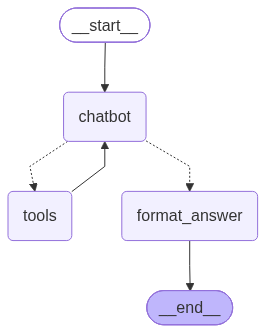

In [8]:
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode

tools = [web_search]
llm_with_tools = llm.bind_tools(tools)

SYSTEM_PROMPT = SystemMessage(content=(
    f"You are a helpful research assistant. Today's date is {date.today()}. "
    "Use web_search for anything recent or that you are unsure about."
))

FORMAT_PROMPT = SystemMessage(content=(
    "Turn the conversation above into the final answer for the user's LAST question. "
    "Only use facts from the search results. Copy source URLs exactly."
))


class AgentState(MessagesState):
    final_answer: SearchAnswer | None


def chatbot(state: AgentState):
    return {"messages": [llm_with_tools.invoke([SYSTEM_PROMPT] + state["messages"])]}


def format_answer(state: AgentState):
    answer = structured_llm.invoke(state["messages"] + [FORMAT_PROMPT])
    return {"final_answer": answer}


def route(state: AgentState):
    # Our own version of tools_condition, with a different "else" target
    if state["messages"][-1].tool_calls:
        return "tools"
    return "format_answer"


builder = StateGraph(AgentState)
builder.add_node("chatbot", chatbot)
builder.add_node("tools", ToolNode(tools))
builder.add_node("format_answer", format_answer)

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", route, ["tools", "format_answer"])
builder.add_edge("tools", "chatbot")
builder.add_edge("format_answer", END)

agent = builder.compile()

from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [9]:
result = agent.invoke({"messages": [HumanMessage(content="What is the latest version of Python?")]})

final = result["final_answer"]
print(type(final))
print(final.model_dump_json(indent=2))

<class '__main__.SearchAnswer'>
{
  "answer": "The latest version of Python is Python 3.15.1, released on October 21, 2026.",
  "key_points": [
    "Python 3.15.1 is the newest release, dated Oct. 21, 2026",
    "Python 3.15.0 was released Oct. 9, 2026",
    "The latest 3.14.x release is Python 3.14.9 (Oct. 21, 2026)",
    "Downloads are available at python.org/downloads"
  ],
  "sources": [
    "https://www.python.org/downloads"
  ],
  "confidence": "high"
}


## 7. Pretty display

Because the answer is an object (not a blob of text), *we* decide how it looks:
Markdown in the notebook, JSON for an API, HTML for a website...

In [10]:
from IPython.display import Markdown

CONFIDENCE_ICON = {"high": "🟢", "medium": "🟡", "low": "🔴"}


def render(ans: SearchAnswer) -> str:
    points = "\n".join(f"- {p}" for p in ans.key_points)
    sources = "\n".join(f"{i}. {url}" for i, url in enumerate(ans.sources, start=1)) or "_none_"
    return (
        f"### {ans.answer}\n\n"
        f"**Key points**\n{points}\n\n"
        f"**Confidence:** {CONFIDENCE_ICON[ans.confidence]} {ans.confidence}\n\n"
        f"**Sources**\n{sources}"
    )


display(Markdown(render(final)))

### The latest version of Python is Python 3.15.1, released on October 21, 2026.

**Key points**
- Python 3.15.1 is the newest release, dated Oct. 21, 2026
- Python 3.15.0 was released Oct. 9, 2026
- The latest 3.14.x release is Python 3.14.9 (Oct. 21, 2026)
- Downloads are available at python.org/downloads

**Confidence:** 🟢 high

**Sources**
1. https://www.python.org/downloads

### Interactive chat with formatted answers

Memory works the same as before (checkpointer + `thread_id`). Type `quit` to stop.

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver

agent = builder.compile(checkpointer=InMemorySaver())


def chat(thread_id: str = "formatted-chat-1"):
    config = {"configurable": {"thread_id": thread_id}}
    print("Chat started. Type 'quit' to stop.\n")
    while True:
        user_input = input("You: ")
        if user_input.strip().lower() in {"quit", "exit", "q"}:
            print("Goodbye! 👋")
            break
        result = agent.invoke({"messages": [HumanMessage(content=user_input)]}, config)
        display(Markdown(render(result["final_answer"])))


chat()

Chat started. Type 'quit' to stop.



## Recap

- **Tool docstring** → the description the model reads to decide *when/how* to call it. Be specific.
- **`parse_docstring=True`** + `Args:` section → a description for every argument.
- **Tool return value** → format it; that's what the model reads.
- **Pydantic docstring + `Field(description=...)`** → controls the *shape* of the answer via `with_structured_output`.
- A **format node** at the end of the graph turns the conversation into a typed object you can display however you like.

### Try it yourself
1. Add a field to `SearchAnswer`, e.g. `follow_up_questions: list[str]`, and show it in `render()`.
2. Change a `Field` description (e.g. "answer in exactly one sentence") and see the output change.
3. Make a different schema, like `MovieInfo(title, year, director, rating)`, and ask about a film.
4. Remove the docstring from `web_search` and see if the agent still uses it correctly.